In [9]:
from pathlib import Path

In [10]:
import cv2, numpy as np
def scope_v0(bgr):
    img = cv2.resize(bgr, (512, 512))
    mask = np.zeros(img.shape[:2], np.uint8)
    rect = (20, 20, 472, 472)
    bg = np.zeros((1,65)); fg = np.zeros((1,65))
    cv2.grabCut(img, mask, rect, bg, fg, 5, cv2.GC_INIT_WITH_RECT)
    leaf = np.where((mask==1)|(mask==3), 1, 0).astype(np.uint8)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    healthy = ((hsv[...,0]>35)&(hsv[...,0]<85)&(hsv[...,1]>40)).astype(np.uint8)
    lesion = (leaf==1)&(healthy==0)
    return 100*lesion.sum()/max(leaf.sum(),1), leaf, lesion

In [11]:
import cv2, numpy as np, pandas as pd, pathlib
pathlib.Path("results/v0").mkdir(parents=True, exist_ok=True)
obs = pd.read_csv("../docs/observations.csv", dtype=str)

def overlay(bgr, leaf, lesion):
    out = cv2.resize(bgr, (512, 512)).copy()
    cnts, _ = cv2.findContours(leaf.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(out, cnts, -1, (255, 0, 0), 2)
    red = np.zeros_like(out); red[lesion] = (0, 0, 255)
    return cv2.addWeighted(out, 1, red, 0.5, 0)

In [12]:
path = Path.cwd().resolve().parent
root = path/"data"/"raw"

In [13]:
rows = []
for r in obs.itertuples():
    bgr = cv2.imread(str(root / r.file))
    s, leaf, lesion = scope_v0(bgr)
    cv2.imwrite(f"results/v0/{r.file.replace('/', '__')}", overlay(bgr, leaf, lesion))
    rows.append(dict(file=r.file, scope_v0=s, leaf_frac=leaf.mean()))
res = pd.DataFrame(rows).merge(obs, on="file")
res.to_csv("results/v0_scope.csv", index=False)
print(res[res.label == "banana_healthy_leaf"].scope_v0.describe())
print((res.leaf_frac < 0.15).sum(), "tiny leaf masks;", (res.leaf_frac > 0.95).sum(), "near-whole-image masks")

count    20.000000
mean      1.116690
std       4.056858
min       0.000000
25%       0.000000
50%       0.000000
75%       0.010870
max      17.977528
Name: scope_v0, dtype: float64
14 tiny leaf masks; 0 near-whole-image masks


30/30


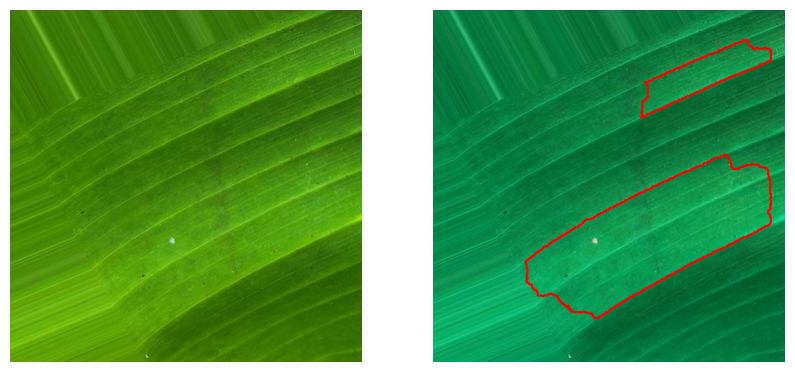

leaf_ok [1=good 2=partial 3=bad]:  2
lesion_ok [1=good 2=partial 3=bad]:  1


In [16]:
import matplotlib.pyplot as plt
from IPython.display import clear_output
classes = ["black_sigatoka", "yellow_sigatoka", "banana_healthy_leaf"]
qa_set = pd.concat([res[res.label == c].sample(10, random_state=1) for c in classes]).reset_index(drop=True)
qa_set["leaf_ok"] = ""; qa_set["lesion_ok"] = ""
for i, r in qa_set.iterrows():
    clear_output(wait=True); print(f"{i+1}/30")        # no filename shown
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(plt.imread(root / r.file)); ax[1].imshow(plt.imread(f"results/v0/{r.file.replace('/', '__')}")[..., ::-1])
    for a in ax: a.axis("off")
    plt.show()
    for col in ["leaf_ok", "lesion_ok"]:
        while True:
            a = input(f"{col} [1=good 2=partial 3=bad]: ").strip()
            if a in ("1", "2", "3"): qa_set.loc[i, col] = a; break
qa_set.to_csv("results/v0_qa.csv", index=False)

In [17]:
print(pd.crosstab([qa_set.label, qa_set.background], qa_set.leaf_ok))
print(pd.crosstab([qa_set.label, qa_set.background], qa_set.lesion_ok))
from scipy.stats import spearmanr
order = {"small": 1, "medium": 2, "large": 3}
d = res[res.label != "banana_healthy_leaf"]
print(spearmanr(d.scope_v0, d.lesion_size.map(order)))

leaf_ok                         1  2  3
label               background         
banana_healthy_leaf field       1  0  0
                    plain       0  7  2
black_sigatoka      field       4  2  2
                    plain       0  0  2
yellow_sigatoka     field       1  1  4
                    plain       1  2  1
lesion_ok                       1  2  3
label               background         
banana_healthy_leaf field       1  0  0
                    plain       9  0  0
black_sigatoka      field       6  2  0
                    plain       2  0  0
yellow_sigatoka     field       4  1  1
                    plain       1  3  0
SignificanceResult(statistic=np.float64(0.3258330870790493), pvalue=np.float64(0.04019180914269269))
